# KAT-Transformer option pricing — single-asset, cross-asset and multi-asset training

The pykan (KAN) section is removed. Only the **KAT-Transformer** (Kolmogorov-Arnold Transformer:
attention + a rational-activation KAN MLP, from Yang's `katransformer.py`) is used, extended to the
full training-regime study from Goswami, Rajani & Tanksale (2021):

| Regime | What it does | Paper |
|---|---|---|
| **Single-asset** | Train and test on the same asset (NIFTY50, BANKNIFTY) | Tables 4, 5 |
| **Cross-asset** | Train on asset A, test on asset B without retraining | Table 8 |
| **Multi-asset (combined)** | Train on pooled data, test on each asset out of sample | Table 9 |
| Benchmark | Black-Scholes with 20-day historical volatility | B-S rows |
| Diagnostics | Band coverage, actual-vs-predicted bias | Figs. 11, 14 |

**Binning is shared across assets.** The bin cutoff (and `NUM_CLASSES`) is computed once on the
*pooled* 100·C/K distribution so a bin index means the same price band on both assets — required for
cross-asset and combined training to be valid, per the paper: *"Without uniform binning, it would not
be possible to combine or compare models trained on different datasets."*

**Note on the original notebook's train/test split.** It restricted both train and test to 2026
dates only, which throws away most of the history. That restriction is removed here in favor of the
paper's ordinary 70:30 chronological split over the full period; an optional `YEAR_FILTER` is left in
the config cell if you want the old behavior back for a quick run.

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

## KAT-Transformer setup

Clones the rational-activation kernels (`rational_kat_cu`, pure PyTorch fallback on CPU, Triton on
GPU) and the transformer definitions (`katransformer.py`, from the `kat` repo) if they are not
already present, then imports `KAN` (the rational-activation MLP block) and `Block` (attention + KAN,
wired together) unmodified.

In [2]:
import os, sys, shutil

if not os.path.exists("rational_kat_cu"):
    !git clone -q https://github.com/adamdad/rational_kat_cu.git
%pip install -q -e rational_kat_cu
%pip install -q timm

if not os.path.exists("katransformer.py"):
    # Prefer a copy already sitting in Drive, if you have one
    drive_copy = "/content/drive/MyDrive/data_files/katransformer.py"
    if os.path.exists(drive_copy):
        shutil.copy(drive_copy, "katransformer.py")
    else:
        if not os.path.exists("kat"):
            !git clone -q https://github.com/Adamdad/kat.git
        shutil.copy("kat/katransformer.py", "katransformer.py")

sys.path.insert(0, "rational_kat_cu")
assert os.path.exists("katransformer.py"), "katransformer.py still missing"
assert os.path.exists("rational_kat_cu"), "rational_kat_cu clone failed"
print("KAT-Transformer sources ready")

  error: subprocess-exited-with-error
  
  × Getting requirements to build editable did not run successfully.
  │ exit code: 1
  ╰─> [24 lines of output]
      Traceback (most recent call last):
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 157, in get_requires_for_build_editable
          return hook(config_settings)
                 ^^^^^^^^^^^^^^^^^^^^^
        File "/tmp/pip-build-env-z_54w75o/overlay/lib/python3.12/site-packages/setuptools/bu

In [3]:
import warnings, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import norm

from katransformer import KAN, Block   # attention + rational-activation KAN MLP, untouched

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", device)

device: cuda


/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/rahulsm21/Documents/BTP/rational_kat_cu/kat_rational/rational_triton.py:244: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/home/rahulsm21/Documents/BTP/rational_kat_cu/kat_rational/rational_triton.py:272: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Plea

## 0. Configuration

In [4]:
DATA_DIR = 'data_files/2021-2026'
BOND_FILE = f"{DATA_DIR}/bond_yield.csv"

ASSET_FILES = {
    'NIFTY50': {
        'options': f"{DATA_DIR}/Nifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/Nifty_Spot.csv",
    },
    'BANKNIFTY': {
        'options': f"{DATA_DIR}/banknifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/BankNifty_Spot.csv",
    },
}

# ---- filtering / binning (paper values) --------------------------------
LOOKBACK   = 20
DTE_MIN, DTE_MAX = 3, 45
ATM_BAND   = 0.04
W_BIN      = 0.1        # bin width on the 100*C/K scale
BIN_COVER  = 98.0        # percentile of pooled data below the overflow bin
TRAIN_FRAC = 0.70
OPTION_TYPE = 'CE'
SEED = 42

YEAR_FILTER = None       # e.g. 2026 to reproduce the original notebook's 2026-only split; None = full history

USE_ALL_OHLC_MEANS = True   # True -> paper's 17/19-feature Approach II/III; False -> mu_C-only variant

# ---- KAT-Transformer hyperparameters (same defaults as the original notebook) ----
EMBED_DIM  = 64
DEPTH      = 4
NUM_HEADS  = 4
MLP_RATIO  = 2.0
ACT_INIT   = "gelu"      # or "swish"
DROP_RATE  = 0.1
LR         = 1.2e-4
BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE   = 6            # early stopping on validation loss
VAL_FRAC   = 0.15
PRED_CHUNK = 2048

QUICK_MODE = False         # True -> tiny model / few epochs, for a fast end-to-end dry run
if QUICK_MODE:
    EMBED_DIM, DEPTH, NUM_HEADS = 16, 2, 2
    MAX_EPOCHS, PATIENCE = 4, 2

print("Assets:", list(ASSET_FILES))

Assets: ['NIFTY50', 'BANKNIFTY']


## 1. Data pipeline (per asset)

In [5]:
def load_bond_yields(path):
    bonds = pd.read_csv(path)
    bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
    bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
    for c in ['risk_free_rate', 'rf_open', 'rf_high', 'rf_low']:
        bonds[c] = pd.to_numeric(bonds[c].astype(str).str.replace(',', ''), errors='coerce')
    bonds.loc[bonds['risk_free_rate'] > 50, 'risk_free_rate'] = np.nan   # sentinel prints
    bonds = bonds.dropna(subset=['date']).sort_values('date')
    bonds['risk_free_rate'] = bonds['risk_free_rate'].ffill().bfill()
    full = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
    return (bonds.set_index('date')[['risk_free_rate']]
                 .reindex(full).rename_axis('date').ffill().reset_index())


def load_spot(path):
    spot = pd.read_csv(path)
    spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
    spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
    for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
        spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
    return spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)


def load_options(path):
    opt = pd.read_csv(path).drop(columns=['Unnamed: 0'], errors='ignore')
    opt.columns = ['symbol', 'date', 'expiry', 'option_type', 'strike',
                   'open', 'high', 'low', 'close', 'ltp', 'settle_price',
                   'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
                   'open_interest', 'change_in_oi', 'underlying']
    opt['date'] = pd.to_datetime(opt['date'], format='%d-%b-%Y', errors='coerce')
    opt['expiry'] = pd.to_datetime(opt['expiry'], format='%d-%b-%Y', errors='coerce')
    for c in ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price', 'contracts',
              'turnover_lakhs', 'premium_turnover_lakhs', 'open_interest', 'change_in_oi',
              'underlying']:
        opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')
    opt['option_type'] = opt['option_type'].str.strip().str.upper()
    return opt.dropna(subset=['date', 'expiry', 'strike'])


def build_lookback_frame(spot, lookback=LOOKBACK):
    lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
    for lag in range(1, lookback + 1):
        lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
        lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
        lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
        lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)
    return (lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close'])
              .dropna().reset_index(drop=True))


def build_asset_dataset(name, files, bonds, verbose=True):
    counts = {}
    opt = load_options(files['options'])
    counts['raw'] = len(opt)
    spot = load_spot(files['spot'])

    opt = opt.merge(spot[['date', 'spot_close']], on='date', how='left')
    opt['underlying'] = opt['spot_close']
    opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])

    if OPTION_TYPE is not None:
        opt = opt[opt['option_type'] == OPTION_TYPE]
    opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)]

    opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days
    opt = opt[(opt['days_to_expiry'] >= DTE_MIN) & (opt['days_to_expiry'] <= DTE_MAX)]

    opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()
    opt = opt[opt['moneyness_gap'] <= ATM_BAND]

    opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date'])
    opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)
    opt = opt.dropna(subset=['prev_day_close'])

    opt = opt.merge(build_lookback_frame(spot), on='date', how='inner')
    opt = opt.merge(spot, on='date', how='left')
    opt = opt.merge(bonds, on='date', how='left')
    opt['risk_free_rate'] = opt['risk_free_rate'].ffill().bfill()
    opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0
    opt['asset'] = name

    if YEAR_FILTER is not None:
        opt = opt[opt['date'].dt.year == YEAR_FILTER]

    opt = opt.sort_values('date').reset_index(drop=True)
    counts['filtered'] = len(opt)
    if verbose:
        print(f"[{name}] raw={counts['raw']:,}  filtered={counts['filtered']:,}  "
              f"({opt['date'].min().date()} to {opt['date'].max().date()})")
    return opt, counts

In [6]:
bonds = load_bond_yields(BOND_FILE)

DATA, COUNTS = {}, {}
for name, files in ASSET_FILES.items():
    DATA[name], COUNTS[name] = build_asset_dataset(name, files, bonds)

ASSETS = list(DATA)
MULTI_ASSET = len(ASSETS) >= 2
print("\nassets loaded:", ASSETS, "| multi-asset regimes enabled:", MULTI_ASSET)

[NIFTY50] raw=708,909  filtered=126,566  (2021-01-04 to 2026-07-07)
[BANKNIFTY] raw=656,347  filtered=95,238  (2021-01-04 to 2026-06-25)

assets loaded: ['NIFTY50', 'BANKNIFTY'] | multi-asset regimes enabled: True


## 2. Shared binning across assets

In [7]:
pooled_ratio = pd.concat([100 * d['close'] / d['strike'] for d in DATA.values()], ignore_index=True)
pooled_raw = np.ceil(pooled_ratio / W_BIN).astype(int).clip(lower=1)

counts_sorted = pooled_raw.value_counts().sort_index()
cum_pct = counts_sorted.cumsum() / counts_sorted.sum() * 100
CUTOFF_BIN = int(cum_pct[cum_pct <= BIN_COVER].index.max())
NUM_CLASSES = CUTOFF_BIN + 1

print(f"Pooled data: bins 1-{CUTOFF_BIN} cover ~{BIN_COVER}%  ->  NUM_CLASSES = {NUM_CLASSES}")

for name, d in DATA.items():
    d['output_ratio'] = 100 * d['close'] / d['strike']
    d['bin_label_raw'] = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(d['bin_label_raw'] > CUTOFF_BIN, NUM_CLASSES, d['bin_label_raw'])
    share = 100 * (d['bin_label'] == NUM_CLASSES).mean()
    print(f"[{name}] bins {d['bin_label'].min()}-{d['bin_label'].max()}, "
          f"overflow bin holds {share:.2f}% of rows")

Pooled data: bins 1-44 cover ~98.0%  ->  NUM_CLASSES = 45
[NIFTY50] bins 1-45, overflow bin holds 1.53% of rows
[BANKNIFTY] bins 1-45, overflow bin holds 3.57% of rows


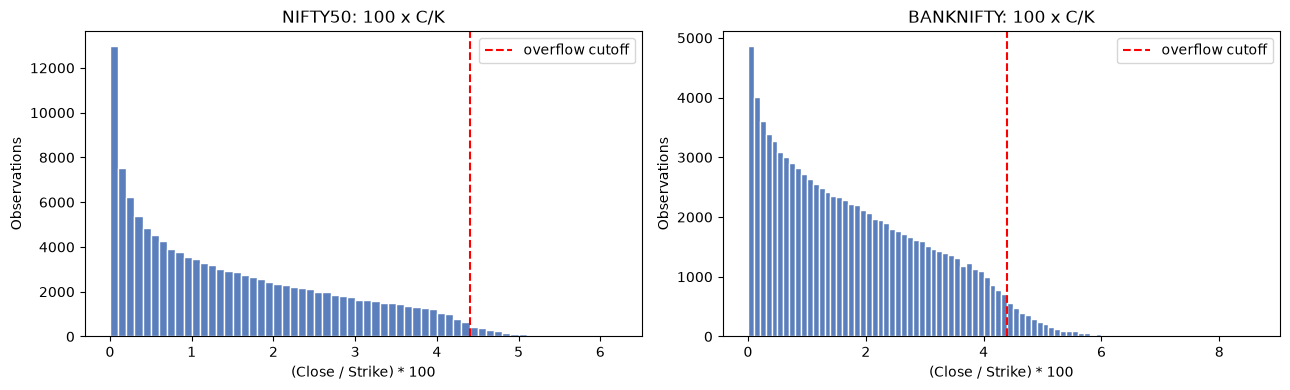

In [8]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6.5*len(DATA), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], DATA.items()):
    ax.hist(d['output_ratio'], bins=np.arange(0, d['output_ratio'].max()+W_BIN, W_BIN),
            color='#5b7fbd', edgecolor='white')
    ax.axvline(CUTOFF_BIN * W_BIN, color='red', ls='--', label='overflow cutoff')
    ax.set_xlabel('(Close / Strike) * 100'); ax.set_ylabel('Observations')
    ax.set_title(f'{name}: 100 x C/K'); ax.legend()
plt.tight_layout(); plt.show()

## 3. Feature sets — Approaches I, II, III

Identical columns and order for every asset, so a model trained on one asset can score another
asset's matrix directly.

In [9]:
def log_returns_from_lookback(df, field, lookback=LOOKBACK):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(lookback, 0, -1)]
    return np.diff(np.log(df[cols_chrono].values.astype(float)), axis=1)


def signed_sqrt(x):
    out = np.zeros_like(x)
    m = x != 0
    out[m] = x[m] / np.sqrt(np.abs(x[m]))
    return out


def contract_block(df):
    return pd.DataFrame({
        'moneyness':        (df['underlying'] / df['strike']).values,
        'time_to_maturity': df['days_to_expiry'].values.astype(float),
        'interest_rate':    df['risk_free_rate'].values.astype(float),
    }, index=df.index)


def build_approach1(df):
    os_close = np.sort(log_returns_from_lookback(df, 'close'), axis=1)
    X = pd.DataFrame(os_close, columns=[f'os_close_{i+1}' for i in range(os_close.shape[1])],
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach2(df):
    lr_o = log_returns_from_lookback(df, 'open')
    lr_h = log_returns_from_lookback(df, 'high')
    lr_l = log_returns_from_lookback(df, 'low')
    lr_c = log_returns_from_lookback(df, 'close')

    stack = np.stack([lr_o, lr_h, lr_l, lr_c], axis=1)
    centered = stack - stack.mean(axis=2, keepdims=True)
    cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)
    cov_t = signed_sqrt(cov)

    labels = ['O', 'H', 'L', 'C']
    cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_t[:, i, j]
                for i in range(4) for j in range(i + 1)}

    means = ({'mu_O': lr_o.mean(axis=1), 'mu_H': lr_h.mean(axis=1),
              'mu_L': lr_l.mean(axis=1), 'mu_C': lr_c.mean(axis=1)}
             if USE_ALL_OHLC_MEANS else {'mu_C': lr_c.mean(axis=1)})

    X = pd.DataFrame({**means, **cov_cols}, index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach3(df):
    X = build_approach2(df).drop(columns=['bin_label'])
    X['prev_option_price_scaled'] = (df['prev_day_close'] / df['strike']).values
    lookback_close_cols = [f'und_close_lag{i}' for i in range(1, LOOKBACK + 1)]
    X['mean_moneyness'] = (df[lookback_close_cols].mean(axis=1) / df['strike']).values
    X['bin_label'] = df['bin_label'].values
    return X


APPROACH_BUILDERS = {'Approach I': build_approach1,
                     'Approach II': build_approach2,
                     'Approach III': build_approach3}
APPROACHES = list(APPROACH_BUILDERS)

In [10]:
FEATURES = {name: {ap: fn(d) for ap, fn in APPROACH_BUILDERS.items()}
            for name, d in DATA.items()}

print("Feature counts (excl. label):")
print(pd.DataFrame({ap: {n: FEATURES[n][ap].shape[1]-1 for n in FEATURES} for ap in APPROACHES}))

for ap in APPROACHES:
    cols = [list(FEATURES[n][ap].columns) for n in ASSETS]
    assert all(c == cols[0] for c in cols), f"column mismatch in {ap}"
print("\nColumn alignment across assets: OK")

Feature counts (excl. label):
           Approach I  Approach II  Approach III
NIFTY50            22           17            19
BANKNIFTY          22           17            19

Column alignment across assets: OK


## 4. Train / test split and metrics

In [11]:
SPLIT = {}
for name, d in DATA.items():
    dates = np.sort(d['date'].unique())
    cutoff = dates[int(len(dates) * TRAIN_FRAC) - 1]
    SPLIT[name] = {'train': (d['date'] <= cutoff).values,
                   'test':  (d['date'] > cutoff).values,
                   'cutoff': pd.Timestamp(cutoff)}
    COUNTS[name].update(train=int(SPLIT[name]['train'].sum()),
                        test=int(SPLIT[name]['test'].sum()))
    print(f"[{name}] cutoff {pd.Timestamp(cutoff).date()} | "
          f"train {COUNTS[name]['train']:,} | test {COUNTS[name]['test']:,}")

print()
print(pd.DataFrame(COUNTS).loc[['raw', 'filtered', 'train', 'test']])

[NIFTY50] cutoff 2024-11-11 | train 79,485 | test 47,081
[BANKNIFTY] cutoff 2024-11-07 | train 76,505 | test 18,733

          NIFTY50  BANKNIFTY
raw        708909     656347
filtered   126566      95238
train       79485      76505
test        47081      18733


In [12]:
def em_metric(actual, pred, bin_width=W_BIN):
    return bin_width * np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)))

def rho_metric(actual, pred):
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)) > 2)

def acc_metric(actual, pred):
    return np.mean(np.round(np.asarray(pred, float)) == np.asarray(actual, float))

def split_xy(feat_df, mask):
    cols = [c for c in feat_df.columns if c != 'bin_label']
    return (feat_df.loc[mask, cols].values.astype(np.float32),
            feat_df.loc[mask, 'bin_label'].values.astype(np.int64),
            cols)

## 5. KAT-Transformer model and training

`FeatureTokenizer` + `KATTabularTransformer` are unchanged from the original notebook: each tabular
feature gets its own learned linear embedding (FT-Transformer style), a `[CLS]` token is prepended,
and the sequence runs through `Block` (attention + the rational-activation KAN MLP) from
`katransformer.py`.

Training now uses a held-out validation split with early stopping, so the same routine works whether
the training set has 7,000 rows (single-asset) or 14,000 (combined) without hand-tuning an epoch
count per regime.

In [13]:
EMBED_DIM, DEPTH, NUM_HEADS, MLP_RATIO = 32, 2, 4, 2.0   # was 64 / 4 (and the old code ignored them)
DROP_RATE = 0.1

TOKENIZER  = 'periodic'   # 'linear' reproduces the old tokenizer
N_FREQ     = 8
FREQ_SIGMA = 0.1          # main knob: 0.05-0.2 smooth, larger overfits
USE_WIDE   = True         # linear skip from raw features to logits
CLIP       = 5.0

LABEL_SIGMA, DECODE, ENSEMBLE_SEEDS, WEIGHT_DECAY = 1.0, 'median', 3, 1e-2

In [14]:
import math

for _k, _v in dict(TOKENIZER='periodic', N_FREQ=8, FREQ_SIGMA=0.1, USE_WIDE=True).items():
    globals().setdefault(_k, _v)


class FeatureTokenizer(nn.Module):
    """(B, F) -> (B, F, D). 'linear' = original per-feature affine embedding.
    'periodic' = sin/cos features of each scalar (learned frequencies) + raw value,
    projected per feature, so a feature's token can be a curved function of its value."""
    def __init__(self, n_features, embed_dim, kind='periodic', n_freq=8, freq_sigma=0.1):
        super().__init__()
        self.kind = kind
        self.bias = nn.Parameter(torch.zeros(n_features, embed_dim))
        if kind == 'linear':
            self.weight = nn.Parameter(torch.randn(n_features, embed_dim) * 0.02)
        else:
            self.freq = nn.Parameter(torch.randn(n_features, n_freq) * freq_sigma)
            k = 2 * n_freq + 1
            self.proj = nn.Parameter(torch.randn(n_features, k, embed_dim) / math.sqrt(k))

    def forward(self, x):                                       # x: (B, F)
        if self.kind == 'linear':
            return x.unsqueeze(-1) * self.weight + self.bias
        v = 2 * math.pi * x.unsqueeze(-1) * self.freq           # (B, F, n_freq)
        f = torch.cat([torch.sin(v), torch.cos(v), x.unsqueeze(-1)], dim=-1)
        return torch.einsum('bfk,fkd->bfd', f, self.proj) + self.bias


class KATTabularTransformer(nn.Module):
    def __init__(self, n_features, num_classes, embed_dim=32, depth=2, num_heads=4,
                 mlp_ratio=2.0, act_init="gelu", drop_rate=0.1,
                 tokenizer='periodic', n_freq=8, freq_sigma=0.1, use_wide=True):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_features, embed_dim, tokenizer, n_freq, freq_sigma)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.tok_drop  = nn.Dropout(drop_rate)
        # no pos_embed: each feature already has its own tokenizer weights, so it knows which feature it is

        self.blocks = nn.ModuleList([
            Block(dim=embed_dim, num_heads=num_heads, mlp_ratio=mlp_ratio, qkv_bias=True,
                  proj_drop=drop_rate, attn_drop=drop_rate,
                  mlp_layer=KAN, act_init=act_init)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.wide = None
        if use_wide:                                            # linear skip: raw features -> logits
            self.wide = nn.Linear(n_features, num_classes)
            nn.init.zeros_(self.wide.weight); nn.init.zeros_(self.wide.bias)

        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):                                       # x: (B, F)
        tokens = self.tokenizer(x)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        tokens = self.tok_drop(torch.cat([cls, tokens], dim=1))
        for blk in self.blocks:
            tokens = blk(tokens)
        out = self.head(self.norm(tokens)[:, 0])
        if self.wide is not None:
            out = out + self.wide(x)
        return out

In [15]:
import torch.nn.functional as F

for _k, _v in dict(LABEL_SIGMA=1.0, DECODE='median', ENSEMBLE_SEEDS=3,
                   WEIGHT_DECAY=1e-2, CLIP=5.0).items():
    globals().setdefault(_k, _v)


def standardize_fit(X):
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True)
    std[std < 1e-8] = 1e-8
    return mean, std


def prep(X, mean, std):
    return np.clip((X - mean) / std, -CLIP, CLIP)     # crash-period inputs sit far outside training range


def split_val(X, y, frac=VAL_FRAC, seed=SEED, dates=None):
    """Chronological hold-out (last `frac` of dates). Same-day contracts are near-duplicates,
    so a random split leaks. If `dates` is None, rows are assumed date-sorted."""
    if dates is None:
        cut = int(X.shape[0] * (1 - frac))
        return X[:cut], y[:cut], X[cut:], y[cut:]
    t = np.asarray(dates).astype('datetime64[ns]').astype('int64')
    is_val = t > np.quantile(t, 1 - frac)
    return X[~is_val], y[~is_val], X[is_val], y[is_val]


def soft_ce(logits, y_idx, sigma=None):
    sigma = LABEL_SIGMA if sigma is None else sigma
    if sigma <= 0:
        return F.cross_entropy(logits, y_idx)
    k = torch.arange(logits.shape[1], device=logits.device, dtype=logits.dtype).unsqueeze(0)
    q = torch.exp(-0.5 * ((k - y_idx.unsqueeze(1).to(logits.dtype)) / sigma) ** 2)
    q = q / q.sum(dim=1, keepdim=True)
    return -(q * F.log_softmax(logits, dim=1)).sum(dim=1).mean()


def _fit_one(X_full, y_full, num_classes, seed, dates=None, tag="", verbose=False):
    X_tr_raw, y_tr, X_val_raw, y_val = split_val(X_full, y_full, VAL_FRAC, seed, dates)
    mean, std = standardize_fit(X_tr_raw)
    X_tr, X_val = prep(X_tr_raw, mean, std), prep(X_val_raw, mean, std)

    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32),
                                      torch.tensor(y_tr - 1, dtype=torch.long)),
                        batch_size=BATCH_SIZE, shuffle=True)
    X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_t = torch.tensor(y_val - 1, dtype=torch.long).to(device)

    model = KATTabularTransformer(
        n_features=X_tr.shape[1], num_classes=num_classes,
        embed_dim=EMBED_DIM, depth=DEPTH, num_heads=NUM_HEADS, mlp_ratio=MLP_RATIO,
        act_init=ACT_INIT, drop_rate=DROP_RATE,
        tokenizer=TOKENIZER, n_freq=N_FREQ, freq_sigma=FREQ_SIGMA, use_wide=USE_WIDE).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best, best_state, bad = float('inf'), None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); tot = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = soft_ce(model(xb), yb)
            loss.backward(); opt.step()
            tot += loss.item() * xb.size(0)
        model.eval()
        with torch.no_grad():
            vl = soft_ce(model(X_val_t), y_val_t).item()
        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"    {tag} seed {seed} ep {epoch:3d} train {tot/len(y_tr):.4f} val {vl:.4f}")
        if vl < best - 1e-4:
            best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    if best_state is not None:
        model.load_state_dict(best_state)
    return {'model': model, 'mean': mean, 'std': std, 'num_classes': num_classes,
            'n_features': X_tr.shape[1], 'val_loss': best, 'epochs_run': epoch}


def fit_kat(X_train_full, y_train_full, num_classes=None, seed=SEED, tag="",
            verbose=False, dates=None):
    num_classes = num_classes or NUM_CLASSES
    members = [_fit_one(X_train_full, y_train_full, num_classes, seed + 1000 * i, dates, tag, verbose)
               for i in range(ENSEMBLE_SEEDS)]
    return {'members': members, 'num_classes': num_classes,
            'val_loss': float(np.mean([m['val_loss'] for m in members])),
            'epochs_run': [m['epochs_run'] for m in members]}


@torch.no_grad()
def predict_proba(bundle, X_raw, chunk=PRED_CHUNK):
    members = bundle.get('members', [bundle])
    total = None
    for m in members:
        m['model'].eval()
        Xs = prep(X_raw, m['mean'], m['std'])
        p = np.concatenate([
            torch.softmax(m['model'](torch.tensor(Xs[s:s+chunk], dtype=torch.float32).to(device)),
                          dim=1).cpu().numpy()
            for s in range(0, len(Xs), chunk)])
        total = p if total is None else total + p
    return total / len(members)


def decode_bins(probs, mode=None):
    mode = mode or DECODE
    if mode == 'argmax':
        return probs.argmax(axis=1) + 1
    return (probs.cumsum(axis=1) >= 0.5).argmax(axis=1) + 1      # median bin


def predict_bins(bundle, X_raw, chunk=PRED_CHUNK):
    return decode_bins(predict_proba(bundle, X_raw, chunk))


def score(bundle, X_raw, y_true):
    pred = predict_bins(bundle, X_raw)
    return pred, {'EM': em_metric(y_true, pred), 'rho': rho_metric(y_true, pred),
                  'A': acc_metric(y_true, pred)}

In [16]:
# class FeatureTokenizer(nn.Module):
#     """Turns a (batch, n_features) tabular row into a (batch, n_features, embed_dim)
#     token sequence -- one learned linear embedding per feature, à la FT-Transformer.
#     Everything downstream (attention + KAN MLP) is the untouched KAT Block."""
#     def __init__(self, n_features, embed_dim):
#         super().__init__()
#         self.weight = nn.Parameter(torch.randn(n_features, embed_dim) * 0.02)
#         self.bias   = nn.Parameter(torch.zeros(n_features, embed_dim))

#     def forward(self, x):                      # x: (B, n_features)
#         return x.unsqueeze(-1) * self.weight + self.bias   # (B, n_features, embed_dim)


# class KATTabularTransformer(nn.Module):
#     def __init__(
#         self,
#         n_features,
#         num_classes,
#         embed_dim=64,
#         depth=4,
#         num_heads=4,
#         mlp_ratio=2.0,
#         act_init="gelu",     # or "swish" -- matches katransformer's act_init options
#         drop_rate=0.1,
#     ):
#         super().__init__()
#         self.tokenizer = FeatureTokenizer(n_features, embed_dim)
#         self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
#         self.pos_embed = nn.Parameter(torch.randn(1, n_features + 1, embed_dim) * 0.02)
#         self.pos_drop  = nn.Dropout(drop_rate)

#         self.blocks = nn.ModuleList([
#             Block(
#                 dim=embed_dim,
#                 num_heads=num_heads,
#                 mlp_ratio=mlp_ratio,
#                 qkv_bias=True,
#                 proj_drop=drop_rate,
#                 attn_drop=drop_rate,
#                 mlp_layer=KAN,      # <-- the KAN (rational-activation) MLP from katransformer.py
#                 act_init=act_init,
#             )
#             for _ in range(depth)
#         ])

#         self.norm = nn.LayerNorm(embed_dim)
#         self.head = nn.Linear(embed_dim, num_classes)

#         nn.init.trunc_normal_(self.cls_token, std=0.02)

#     def forward(self, x):                       # x: (B, n_features)
#         tokens = self.tokenizer(x)               # (B, n_features, D)
#         cls = self.cls_token.expand(x.shape[0], -1, -1)
#         tokens = torch.cat([cls, tokens], dim=1)  # (B, n_features+1, D)
#         tokens = tokens + self.pos_embed
#         tokens = self.pos_drop(tokens)

#         for blk in self.blocks:
#             tokens = blk(tokens)

#         tokens = self.norm(tokens)
#         cls_out = tokens[:, 0]                    # pooled representation
#         return self.head(cls_out)

In [17]:
# def standardize_fit(X):
#     mean = X.mean(axis=0, keepdims=True)
#     std = X.std(axis=0, keepdims=True)
#     std[std < 1e-8] = 1e-8
#     return mean, std


# def split_val(X, y, frac=VAL_FRAC, seed=SEED):
#     rng = np.random.RandomState(seed)
#     idx = rng.permutation(X.shape[0])
#     n_val = max(1, int(X.shape[0] * frac))
#     return X[idx[n_val:]], y[idx[n_val:]], X[idx[:n_val]], y[idx[:n_val]]


# def fit_kat(X_train_full, y_train_full, num_classes=None, seed=SEED, tag="", verbose=False):
#     num_classes = num_classes or NUM_CLASSES
#     X_tr_raw, y_tr, X_val_raw, y_val = split_val(X_train_full, y_train_full, VAL_FRAC, seed)

#     mean, std = standardize_fit(X_tr_raw)
#     X_tr = (X_tr_raw - mean) / std
#     X_val = (X_val_raw - mean) / std

#     train_loader = DataLoader(
#         TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr - 1, dtype=torch.long)),
#         batch_size=BATCH_SIZE, shuffle=True)
#     X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
#     y_val_t = torch.tensor(y_val - 1, dtype=torch.long).to(device)

#     torch.manual_seed(seed)
#     model = KATTabularTransformer(n_features=X_tr.shape[1], num_classes=num_classes).to(device)
#     optimizer = torch.optim.Adam(model.parameters(), lr=LR)
#     criterion = nn.CrossEntropyLoss()

#     best_loss, best_state, bad = float('inf'), None, 0
#     for epoch in range(1, MAX_EPOCHS + 1):
#         model.train()
#         total_loss = 0.0
#         for xb, yb in train_loader:
#             xb, yb = xb.to(device), yb.to(device)
#             optimizer.zero_grad()
#             loss = criterion(model(xb), yb)
#             loss.backward()
#             optimizer.step()
#             total_loss += loss.item() * xb.size(0)

#         model.eval()
#         with torch.no_grad():
#             val_loss = criterion(model(X_val_t), y_val_t).item()
#         if verbose and (epoch % 5 == 0 or epoch == 1):
#             print(f"    {tag} epoch {epoch:3d}  train_loss {total_loss/len(y_tr):.4f}  val_loss {val_loss:.4f}")

#         if val_loss < best_loss - 1e-4:
#             best_loss, best_state, bad = val_loss, copy.deepcopy(model.state_dict()), 0
#         else:
#             bad += 1
#             if bad >= PATIENCE:
#                 if verbose:
#                     print(f"    {tag} early stopped at epoch {epoch}")
#                 break

#     if best_state is not None:
#         model.load_state_dict(best_state)
#     return {'model': model, 'mean': mean, 'std': std, 'num_classes': num_classes,
#             'n_features': X_tr.shape[1], 'val_loss': best_loss, 'epochs_run': epoch}


# @torch.no_grad()
# def predict_bins(bundle, X_raw, chunk=PRED_CHUNK):
#     bundle['model'].eval()
#     Xs = (X_raw - bundle['mean']) / bundle['std']
#     out = []
#     for s in range(0, len(Xs), chunk):
#         xb = torch.tensor(Xs[s:s+chunk], dtype=torch.float32).to(device)
#         out.append(torch.argmax(bundle['model'](xb), dim=1).cpu().numpy())
#     return np.concatenate(out) + 1


# def score(bundle, X_raw, y_true):
#     pred = predict_bins(bundle, X_raw)
#     return pred, {'EM': em_metric(y_true, pred), 'rho': rho_metric(y_true, pred),
#                   'A': acc_metric(y_true, pred)}

## Experiment 1 — Single-asset training (Tables 4 and 5)

One KAT-Transformer per (asset, approach), trained and tested on the same asset. Bundles are kept in
`SINGLE_BUNDLES` and reused by Experiments 3 and 4 — no retraining.

In [18]:
SINGLE_BUNDLES, SINGLE_PRED = {}, {}
single_rows = []

def run_single_asset(name):
    for ap in APPROACHES:
        X_tr, y_tr, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
        X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])

        print(f"training KAT: {name} / {ap}  (features={X_tr.shape[1]}, train={len(y_tr):,})")
        b = fit_kat(X_tr, y_tr, tag=f"{name} / {ap}")
        b['columns'] = cols
        SINGLE_BUNDLES[(name, ap)] = b

        pred, m = score(b, X_te, y_te)
        SINGLE_PRED[(name, ap)] = {'y_true': y_te, 'pred': pred}
        single_rows.append({'asset': name, 'approach': ap, **m})
        print(f"   -> EM {m['EM']:.4f} | rho {m['rho']:.4f} | A {m['A']:.4f}")

In [19]:
run_single_asset('NIFTY50')

training KAT: NIFTY50 / Approach I  (features=22, train=79,485)
   -> EM 0.1575 | rho 0.2014 | A 0.2340
training KAT: NIFTY50 / Approach II  (features=17, train=79,485)
   -> EM 0.1550 | rho 0.2064 | A 0.2451
training KAT: NIFTY50 / Approach III  (features=19, train=79,485)
   -> EM 0.1267 | rho 0.1508 | A 0.3122


In [20]:
run_single_asset('BANKNIFTY')
single_results = pd.DataFrame(single_rows).set_index(['asset', 'approach']).round(4)
print("=== Tables 4 / 5: single-asset KAT-Transformer ===")
print(single_results)

training KAT: BANKNIFTY / Approach I  (features=22, train=76,505)
   -> EM 0.2570 | rho 0.3879 | A 0.1392
training KAT: BANKNIFTY / Approach II  (features=17, train=76,505)
   -> EM 0.2422 | rho 0.3405 | A 0.1585
training KAT: BANKNIFTY / Approach III  (features=19, train=76,505)
   -> EM 0.1755 | rho 0.2312 | A 0.2229
=== Tables 4 / 5: single-asset KAT-Transformer ===
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1575  0.2014  0.2340
          Approach II   0.1550  0.2064  0.2451
          Approach III  0.1267  0.1508  0.3122
BANKNIFTY Approach I    0.2570  0.3879  0.1392
          Approach II   0.2422  0.3405  0.1585
          Approach III  0.1755  0.2312  0.2229


## Experiment 2 — Black-Scholes benchmark

In [21]:
def black_scholes_call(S, K, T, r, sigma):
    S, K, T = np.asarray(S, float), np.asarray(K, float), np.asarray(T, float)
    r, sigma = np.asarray(r, float), np.asarray(sigma, float)
    T = np.clip(T, 1/365, None); sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def price_to_bin(price, strike):
    ratio = 100 * np.asarray(price, float) / np.asarray(strike, float)
    return np.clip(np.ceil(ratio / W_BIN), 1, NUM_CLASSES).astype(int)


BS = {}
for name, d in DATA.items():
    d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
    sub = d.loc[SPLIT[name]['test']].copy()
    sub['bs_price'] = black_scholes_call(sub['underlying'], sub['strike'],
                                         sub['time_to_maturity_yrs'],
                                         sub['risk_free_rate']/100, sub['hist_vol'])
    bs_bin = price_to_bin(sub['bs_price'], sub['strike'])
    actual = np.clip(sub['bin_label'].values, 1, NUM_CLASSES)
    BS[name] = {'EM': em_metric(actual, bs_bin), 'rho': rho_metric(actual, bs_bin),
                'A': acc_metric(actual, bs_bin), 'frame': sub}
    print(f"[{name}] B-S -> EM {BS[name]['EM']:.4f} | rho {BS[name]['rho']:.4f}")

bs_table = pd.DataFrame({k: {m: v[m] for m in ('EM', 'rho', 'A')} for k, v in BS.items()}).T.round(4)
print("\n=== Black-Scholes benchmark ===")
print(bs_table)

[NIFTY50] B-S -> EM 0.2185 | rho 0.3322
[BANKNIFTY] B-S -> EM 0.3011 | rho 0.4568

=== Black-Scholes benchmark ===
               EM     rho       A
NIFTY50    0.2185  0.3322  0.2221
BANKNIFTY  0.3011  0.4568  0.1527


## Experiment 3 — Cross-asset training and testing (Table 8)

Each single-asset model is applied to the *other* asset's test set, unchanged.

In [22]:
cross_rows = []
if MULTI_ASSET:
    for src in ASSETS:
        for tgt in ASSETS:
            if src == tgt:
                continue
            for ap in APPROACHES:
                X_te, y_te, _ = split_xy(FEATURES[tgt][ap], SPLIT[tgt]['test'])
                _, m = score(SINGLE_BUNDLES[(src, ap)], X_te, y_te)
                cross_rows.append({'trained_on': src, 'tested_on': tgt, 'approach': ap, **m})

    cross_results = (pd.DataFrame(cross_rows)
                     .set_index(['trained_on', 'tested_on', 'approach']).round(4))
    print("=== Table 8: cross-asset transfer ===")
    print(cross_results)

    print("\nSame-asset baseline on the same test sets:")
    print(single_results[['EM', 'rho']])

    print("\nCross minus same-asset EM (negative = the foreign model is better):")
    for r in cross_rows:
        base = single_results.loc[(r['tested_on'], r['approach']), 'EM']
        print(f"  {r['trained_on']:>10} -> {r['tested_on']:<10} {r['approach']:<13} "
              f"{r['EM']:.4f} vs {base:.4f}   delta {r['EM']-base:+.4f}")
else:
    print("Skipped: needs two assets in ASSET_FILES.")

=== Table 8: cross-asset transfer ===
                                       EM     rho       A
trained_on tested_on approach                            
NIFTY50    BANKNIFTY Approach I    0.2149  0.3152  0.2045
                     Approach II   0.1855  0.2731  0.1991
                     Approach III  0.1444  0.1873  0.2792
BANKNIFTY  NIFTY50   Approach I    0.2385  0.3777  0.1366
                     Approach II   0.2255  0.3056  0.1489
                     Approach III  0.1756  0.2311  0.1827

Same-asset baseline on the same test sets:
                            EM     rho
asset     approach                    
NIFTY50   Approach I    0.1575  0.2014
          Approach II   0.1550  0.2064
          Approach III  0.1267  0.1508
BANKNIFTY Approach I    0.2570  0.3879
          Approach II   0.2422  0.3405
          Approach III  0.1755  0.2312

Cross minus same-asset EM (negative = the foreign model is better):
     NIFTY50 -> BANKNIFTY  Approach I    0.2149 vs 0.2570   delta -0.0421

## Experiment 4 — Multi-asset combined training (Table 9)

One KAT-Transformer per approach, trained on the pooled training rows of both assets, then tested out
of sample on each asset separately and on the pooled test set.

In [23]:
COMBINED_BUNDLES, combined_rows = {}, []

if MULTI_ASSET:
    for ap in APPROACHES:
        X_parts, y_parts = [], []
        for name in ASSETS:
            Xa, ya, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
            X_parts.append(Xa); y_parts.append(ya)
        X_tr = np.vstack(X_parts); y_tr = np.concatenate(y_parts)

        print(f"training COMBINED KAT: {ap}  (train rows {len(y_tr):,})")
        b = fit_kat(X_tr, y_tr, tag=f"COMBINED/{ap}")
        b['columns'] = cols
        COMBINED_BUNDLES[ap] = b

        for name in ASSETS:
            X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            pred, m = score(b, X_te, y_te)
            SINGLE_PRED[('COMBINED', ap, name)] = {'y_true': y_te, 'pred': pred}
            combined_rows.append({'approach': ap, 'test_asset': name, **m})
            print(f"   tested on {name:<10} EM {m['EM']:.4f} | rho {m['rho']:.4f}")

        Xp = np.vstack([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[0] for n in ASSETS])
        yp = np.concatenate([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[1] for n in ASSETS])
        _, m = score(b, Xp, yp)
        combined_rows.append({'approach': ap, 'test_asset': 'POOLED', **m})

    combined_results = (pd.DataFrame(combined_rows)
                        .set_index(['approach', 'test_asset']).round(4))
    print("\n=== Table 9: combined (multi-asset) training ===")
    print(combined_results)
else:
    print("Skipped: needs two assets in ASSET_FILES.")

training COMBINED KAT: Approach I  (train rows 155,990)
   tested on NIFTY50    EM 0.1986 | rho 0.2666
   tested on BANKNIFTY  EM 0.2448 | rho 0.3230
training COMBINED KAT: Approach II  (train rows 155,990)
   tested on NIFTY50    EM 0.1936 | rho 0.2494
   tested on BANKNIFTY  EM 0.2261 | rho 0.3029
training COMBINED KAT: Approach III  (train rows 155,990)
   tested on NIFTY50    EM 0.1436 | rho 0.1789
   tested on BANKNIFTY  EM 0.1568 | rho 0.2013

=== Table 9: combined (multi-asset) training ===
                             EM     rho       A
approach     test_asset                        
Approach I   NIFTY50     0.1986  0.2666  0.2236
             BANKNIFTY   0.2448  0.3230  0.1844
             POOLED      0.2117  0.2826  0.2125
Approach II  NIFTY50     0.1936  0.2494  0.2514
             BANKNIFTY   0.2261  0.3029  0.2047
             POOLED      0.2029  0.2646  0.2381
Approach III NIFTY50     0.1436  0.1789  0.3186
             BANKNIFTY   0.1568  0.2013  0.2883
             POOL

## Experiment 5 — All three regimes side by side

=== EM / rho by training regime (lower is better) ===
                         single_EM  single_rho  cross_EM  cross_rho  combined_EM  combined_rho   BS_EM  BS_rho
test_asset approach                                                                                           
NIFTY50    Approach I       0.1575      0.2014    0.2385     0.3777       0.1986        0.2666  0.2185  0.3322
           Approach II      0.1550      0.2064    0.2255     0.3056       0.1936        0.2494  0.2185  0.3322
           Approach III     0.1267      0.1508    0.1756     0.2311       0.1436        0.1789  0.2185  0.3322
BANKNIFTY  Approach I       0.2570      0.3879    0.2149     0.3152       0.2448        0.3230  0.3011  0.4568
           Approach II      0.2422      0.3405    0.1855     0.2731       0.2261        0.3029  0.3011  0.4568
           Approach III     0.1755      0.2312    0.1444     0.1873       0.1568        0.2013  0.3011  0.4568


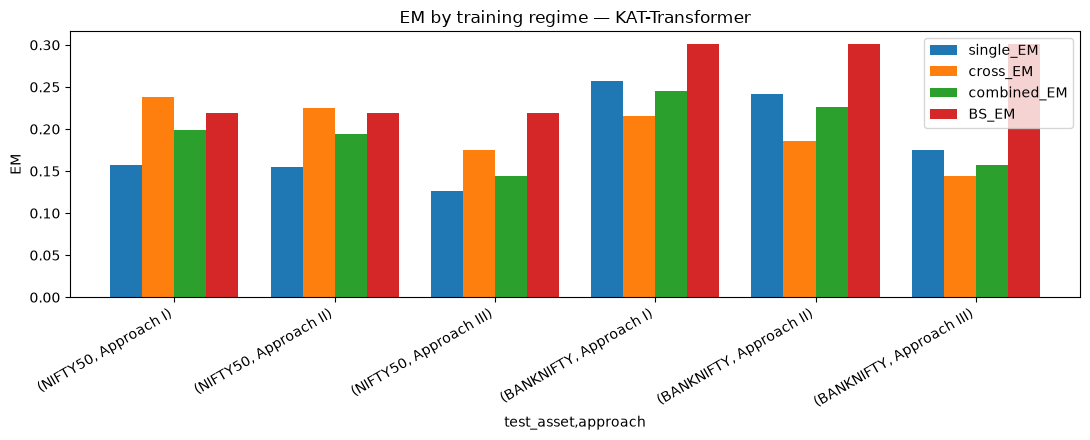


Best regime per (asset, approach):
test_asset  approach    
NIFTY50     Approach I      single_EM
            Approach II     single_EM
            Approach III    single_EM
BANKNIFTY   Approach I       cross_EM
            Approach II      cross_EM
            Approach III     cross_EM
Name: lowest_EM, dtype: str


In [24]:
summary_rows = []
for name in ASSETS:
    for ap in APPROACHES:
        s = single_results.loc[(name, ap)]
        row = {'test_asset': name, 'approach': ap,
               'single_EM': s['EM'], 'single_rho': s['rho']}
        if MULTI_ASSET:
            other = [a for a in ASSETS if a != name][0]
            c = cross_results.loc[(other, name, ap)]
            row.update(cross_EM=c['EM'], cross_rho=c['rho'],
                       combined_EM=combined_results.loc[(ap, name), 'EM'],
                       combined_rho=combined_results.loc[(ap, name), 'rho'])
        row.update(BS_EM=BS[name]['EM'], BS_rho=BS[name]['rho'])
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index(['test_asset', 'approach']).round(4)
print("=== EM / rho by training regime (lower is better) ===")
print(summary)

em_cols = [c for c in summary.columns if c.endswith('_EM')]
ax = summary[em_cols].plot(kind='bar', figsize=(11, 4.5), width=0.8)
ax.set_ylabel('EM'); ax.set_title('EM by training regime — KAT-Transformer')
ax.axhline(0, color='black', lw=0.6)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

if MULTI_ASSET:
    print("\nBest regime per (asset, approach):")
    print(summary[em_cols].idxmin(axis=1).rename('lowest_EM'))

## Experiment 6 — Prediction-band diagnostics (Figs. 11 and 14)

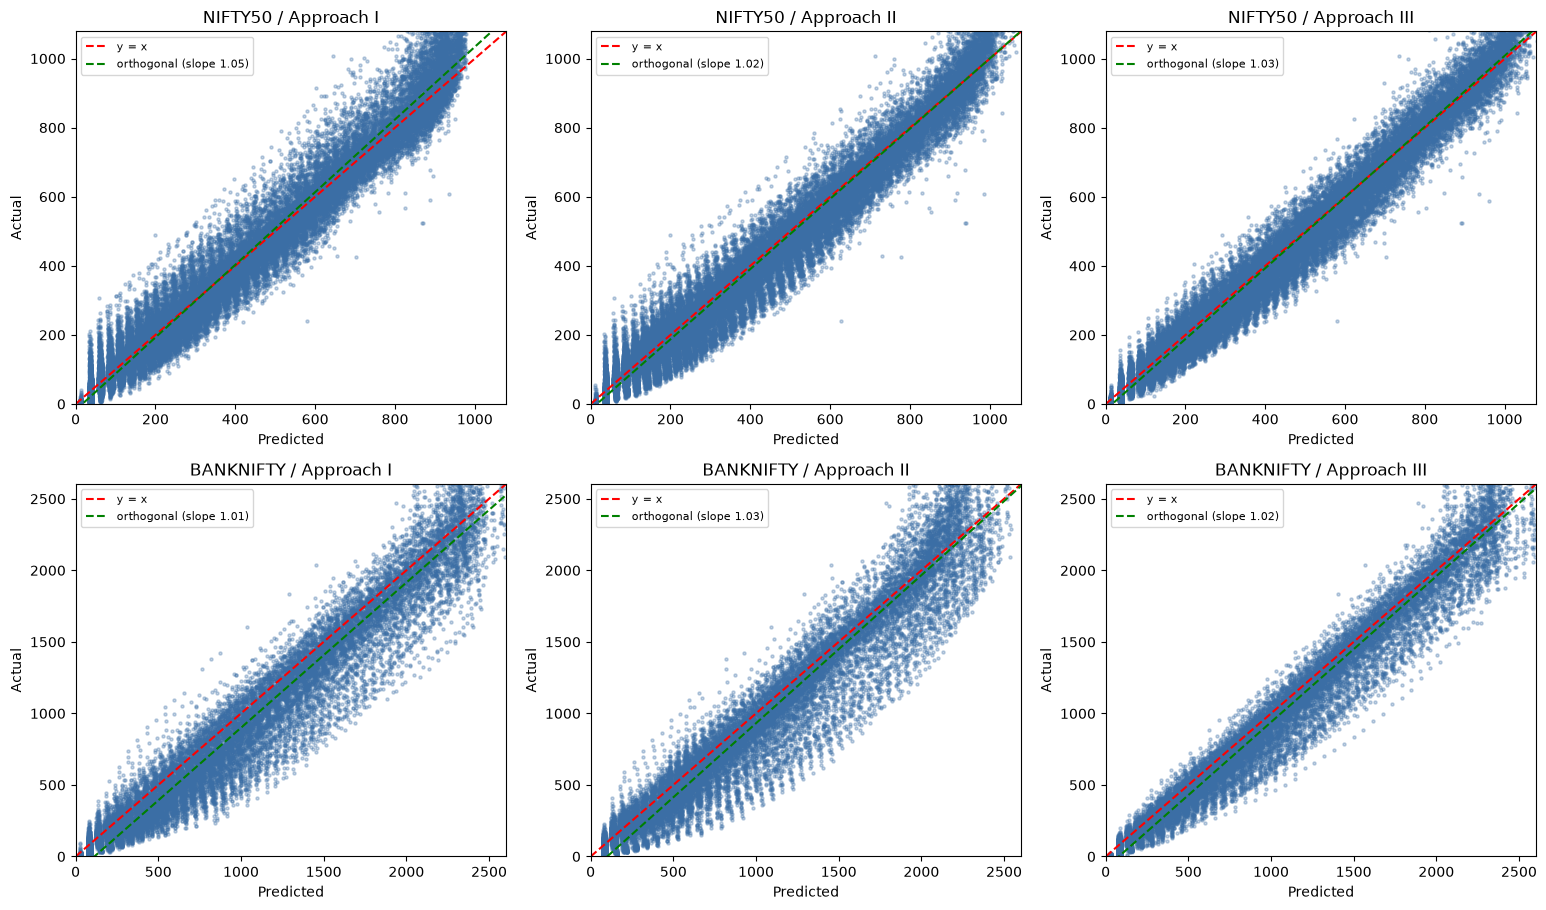

=== Band coverage and bias ===
                        P(|err|<=2)  P(|err|<=5)   q02  q98  tls_slope  mean_signed_error
asset     approach                                                                       
NIFTY50   Approach I         0.7986       0.9665  -4.0  6.0     1.0515            -0.5728
          Approach II        0.7936       0.9791  -5.0  4.0     1.0163             9.9202
          Approach III       0.8492       0.9929  -4.0  4.0     1.0253             7.5797
BANKNIFTY Approach I         0.6121       0.8826 -10.0  3.0     1.0147            99.5219
          Approach II        0.6595       0.8906  -9.0  5.0     1.0349            68.1700
          Approach III       0.7688       0.9423  -7.0  3.0     1.0201            60.5492

1 - rho is the confidence the true bin lies in [P-2, P+2];
mean_signed_error near zero means no systematic over/under-pricing.


In [25]:
def orthogonal_regression(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    xm, ym = x.mean(), y.mean()
    _, _, vt = np.linalg.svd(np.column_stack([x-xm, y-ym]), full_matrices=False)
    vx, vy = vt[0]
    slope = vy/vx
    return slope, ym - slope*xm


def bin_to_price(bins, strike):
    return (np.asarray(bins, float) - 0.5) * W_BIN * np.asarray(strike, float) / 100.0


diag_rows = []
fig, axes = plt.subplots(len(ASSETS), len(APPROACHES), figsize=(5.2*len(APPROACHES), 4.6*len(ASSETS)),
                         squeeze=False)
for i, name in enumerate(ASSETS):
    d_test = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    for j, ap in enumerate(APPROACHES):
        p = SINGLE_PRED[(name, ap)]
        err = p['y_true'].astype(float) - p['pred'].astype(float)
        pred_px = bin_to_price(p['pred'], d_test['strike'].values)
        act_px = d_test['close'].values
        slope, intercept = orthogonal_regression(pred_px, act_px)

        ax = axes[i][j]
        lim = np.nanpercentile(np.concatenate([pred_px, act_px]), 99.5)
        ax.scatter(pred_px, act_px, s=5, alpha=0.3, color='#3b6ea5')
        xs = np.linspace(0, lim, 50)
        ax.plot(xs, xs, 'r--', label='y = x')
        ax.plot(xs, slope*xs + intercept, 'g--', label=f'orthogonal (slope {slope:.2f})')
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f'{name} / {ap}'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.legend(fontsize=8)

        diag_rows.append({'asset': name, 'approach': ap,
                          'P(|err|<=2)': np.mean(np.abs(err) <= 2),
                          'P(|err|<=5)': np.mean(np.abs(err) <= 5),
                          'q02': np.percentile(err, 2), 'q98': np.percentile(err, 98),
                          'tls_slope': slope, 'mean_signed_error': np.mean(pred_px - act_px)})
plt.tight_layout(); plt.show()

diagnostics = pd.DataFrame(diag_rows).set_index(['asset', 'approach']).round(4)
print("=== Band coverage and bias ===")
print(diagnostics)
print("\n1 - rho is the confidence the true bin lies in [P-2, P+2];")
print("mean_signed_error near zero means no systematic over/under-pricing.")

## Summary

In [27]:
print("=" * 80)
print("SINGLE-ASSET (Tables 4/5)"); print(single_results[['EM', 'rho', 'A']])
print("\nBLACK-SCHOLES BENCHMARK"); print(bs_table)
if MULTI_ASSET:
    print("\nCROSS-ASSET (Table 8)"); print(cross_results[['EM', 'rho']])
    print("\nCOMBINED / MULTI-ASSET (Table 9)"); print(combined_results[['EM', 'rho']])
print("\nALL REGIMES"); print(summary)
print("\nBAND COVERAGE / BIAS"); print(diagnostics[['P(|err|<=2)', 'mean_signed_error']])
print("=" * 80)

with pd.ExcelWriter('result/kat_results.xlsx') as xl:
    single_results.to_excel(xl, sheet_name='single_asset')
    bs_table.to_excel(xl, sheet_name='black_scholes')
    if MULTI_ASSET:
        cross_results.to_excel(xl, sheet_name='cross_asset')
        combined_results.to_excel(xl, sheet_name='combined')
    summary.to_excel(xl, sheet_name='all_regimes')
    diagnostics.to_excel(xl, sheet_name='diagnostics')
print("results written to /content/kat_results.xlsx")

SINGLE-ASSET (Tables 4/5)
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1575  0.2014  0.2340
          Approach II   0.1550  0.2064  0.2451
          Approach III  0.1267  0.1508  0.3122
BANKNIFTY Approach I    0.2570  0.3879  0.1392
          Approach II   0.2422  0.3405  0.1585
          Approach III  0.1755  0.2312  0.2229

BLACK-SCHOLES BENCHMARK
               EM     rho       A
NIFTY50    0.2185  0.3322  0.2221
BANKNIFTY  0.3011  0.4568  0.1527

CROSS-ASSET (Table 8)
                                       EM     rho
trained_on tested_on approach                    
NIFTY50    BANKNIFTY Approach I    0.2149  0.3152
                     Approach II   0.1855  0.2731
                     Approach III  0.1444  0.1873
BANKNIFTY  NIFTY50   Approach I    0.2385  0.3777
                     Approach II   0.2255  0.3056
                     Approach III  0.1756  0.2311

COMBINED / MULTI-ASSET (Table 9)
              